# Solutions to notebook 17: Capstone: the onset of Rayleigh–Bénard convection

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/17_capstone_rayleigh_benard.ipynb)

Worked solutions to the exercises at the end of [notebook 17](../notebooks/17_capstone_rayleigh_benard.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eig, expm, solve
from scipy.optimize import minimize_scalar

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 17 (cheb is from notebook 5, clamped_d4 from notebook 14)
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

def helmholtz(k, N):
    """Matrix L of D² − k² on the interior points of the layer 0 < z < 1 (values zero at both plates)."""
    D, x = cheb(N)
    D = 2 * D                                                   # d/dz = 2 d/dx, because z = (x + 1)/2
    return (D @ D)[1:-1, 1:-1] - k**2 * np.eye(N - 1)

def positive_real(eigenvalues):
    """The finite, real, positive eigenvalues in increasing order."""
    lam = eigenvalues[np.isfinite(eigenvalues)]
    lam = lam[(np.abs(lam.imag) < 1e-6 * np.abs(lam)) & (lam.real > 0)]
    return np.sort(lam.real)

def neutral_rayleigh(k, L, L4):
    """Neutral Rayleigh numbers at wavenumber k, lowest first, from the blocks L and L4."""
    n = len(L)
    A = np.block([[L4, np.zeros((n, n))], [np.eye(n), L]])
    B = np.block([[np.zeros((n, n)), k**2 * np.eye(n)], [np.zeros((n, n)), np.zeros((n, n))]])
    return positive_real(eig(A, B, right=False))

def critical_point(ra_of_k, bracket):
    """Minimum of a neutral curve: returns (k_c, Ra_c)."""
    best = minimize_scalar(ra_of_k, bounds=bracket, method="bounded", options={"xatol": 1e-7})
    return best.x, best.fun

def clamped_d4(N):
    """Fourth-derivative matrix on the interior Chebyshev points for functions with u = u' = 0 at x = ±1."""
    D, x = cheb(N)
    D2 = D @ D
    D3, D4 = D2 @ D, D2 @ D2
    weight = np.zeros(N + 1)
    weight[1:-1] = 1 / (1 - x[1:-1] ** 2)
    operator = (np.diag(1 - x**2) @ D4 - 8 * np.diag(x) @ D3 - 12 * D2) @ np.diag(weight)
    return operator[1:-1, 1:-1]

def rigid_blocks(k, N):
    """L and L4 for a layer between two rigid plates."""
    L = helmholtz(k, N)
    identity = np.eye(N - 1)
    D2 = L + k**2 * identity
    return L, 16 * clamped_d4(N) - 2 * k**2 * D2 + k**4 * identity

def ra_rigid_rigid(k, N=20, mode=0):
    return neutral_rayleigh(k, *rigid_blocks(k, N))[mode]

def ra_general(k, N=20, bottom="rigid", top="free"):
    """Lowest neutral Rayleigh number with any combination of rigid and free boundaries (row replacement)."""
    D, x = cheb(N)
    D = 2 * D
    D2, identity, zero = D @ D, np.eye(N + 1), np.zeros((N + 1, N + 1))
    L = D2 - k**2 * identity
    A = np.block([[L @ L, zero], [identity, L]])
    B = np.block([[zero, k**2 * identity], [zero, zero]])
    # index 0 is the top plate z = 1, index N is the bottom plate z = 0
    for edge, neighbour, kind in ((0, 1, top), (N, N - 1, bottom)):
        rows = [edge, neighbour, N + 1 + edge]
        A[rows, :], B[rows, :] = 0.0, 0.0
        A[edge, edge] = 1.0                                              # W = 0
        A[neighbour, :N + 1] = D[edge] if kind == "rigid" else D2[edge]  # DW = 0 or D²W = 0
        A[N + 1 + edge, N + 1 + edge] = 1.0                              # Θ = 0
    return positive_real(eig(A, B, right=False))[0]

def growth_rate(Ra, Pr, k, L, L4):
    """The eigenvalue σ with the largest real part (returned as a complex number)."""
    n = len(L)
    A = np.block([[L4, -Ra * k**2 * np.eye(n)], [np.eye(n), L]])
    B = np.block([[L / Pr, np.zeros((n, n))], [np.zeros((n, n)), np.eye(n)]])
    sigma = eig(A, B, right=False)
    return sigma[np.argmax(sigma.real)]

In [3]:
# the two critical points of the lesson that the exercises refer to
k_rr, Ra_rr = critical_point(ra_rigid_rigid, (2.0, 5.0))
k_rf, Ra_rf = critical_point(ra_general, (1.5, 4.0))
print(f"rigid-rigid: Ra_c = {Ra_rr:.4f}, k_c = {k_rr:.4f}      rigid-free: Ra_c = {Ra_rf:.4f}, k_c = {k_rf:.4f}")
assert abs(Ra_rr - 1707.762) < 5e-4 and abs(Ra_rf - 1100.650) < 5e-4

rigid-rigid: Ra_c = 1707.7618, k_c = 3.1163      rigid-free: Ra_c = 1100.6496, k_c = 2.6823


## Exercise 1

The second entry returned by `neutral_rayleigh` for rigid plates belongs to a mode that is
odd about the mid-plane (two layers of rolls). Compute its neutral curve for
$4 \le k \le 7$ with $N = 30$ and find its minimum. Then explain why this minimum must equal
$16 \times 1100.650$, at twice the wavenumber of the rigid-free case, and confirm both
statements numerically.

The second entry is selected with `mode=1`, and the minimum is found as in the lesson.

**Why 16 times the rigid-free value.** A mode that is odd about the mid-plane $z = \tfrac12$
has $W = 0$ there, and its even derivatives vanish there too, so $D^2W = 0$. The temperature
disturbance is odd as well, $\Theta = 0$. These are exactly the conditions of a free surface
at fixed temperature. Each half of the layer is therefore a rigid-free layer of depth $d/2$
with half the temperature difference across it. The Rayleigh number is proportional to
$\Delta T\,d^3$, so the Rayleigh number of the half layer is $Ra/(2\cdot 2^3) = Ra/16$, and it
must equal 1100.650 at onset. The wavenumber is measured in units of the inverse depth, so
the half layer sees $k/2$: the minimum lies at $k = 2 \times 2.682$.

odd mode between rigid plates: minimum Ra = 17610.394 at k = 5.3647
16 x rigid-free:               16 Ra_c  = 17610.394 at 2 k_c = 5.3646      (16 x 1100.650 = 17610.40)
largest relative difference between the two curves on 4 <= k <= 7: 5.4e-10


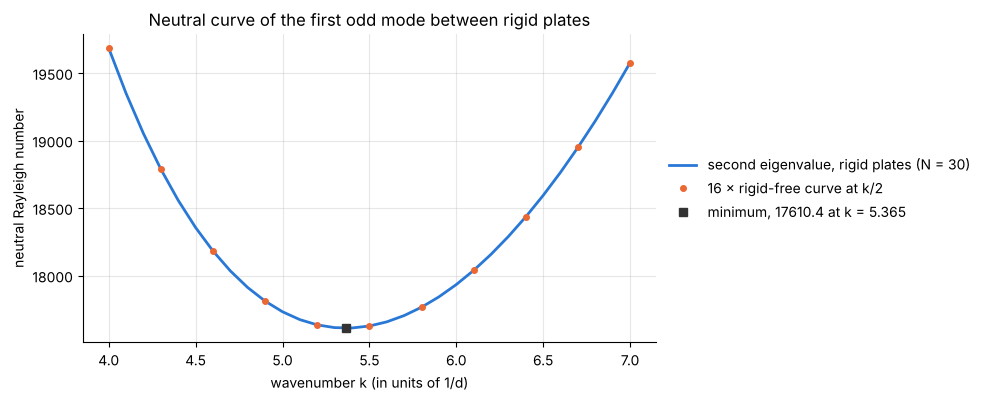

In [4]:
ra_odd = lambda k: ra_rigid_rigid(k, N=30, mode=1)
k_curve = np.linspace(4.0, 7.0, 31)
odd_curve = np.array([ra_odd(k) for k in k_curve])
half_layer_curve = np.array([16 * ra_general(k / 2) for k in k_curve])          # rigid-free layer of half the depth
k_odd, Ra_odd = critical_point(ra_odd, (4.0, 7.0))
print(f"odd mode between rigid plates: minimum Ra = {Ra_odd:.3f} at k = {k_odd:.4f}")
print(f"16 x rigid-free:               16 Ra_c  = {16 * Ra_rf:.3f} at 2 k_c = {2 * k_rf:.4f}      (16 x 1100.650 = {16 * 1100.650:.2f})")
print(f"largest relative difference between the two curves on 4 <= k <= 7: {np.abs(odd_curve / half_layer_curve - 1).max():.1e}")

fig, ax = plt.subplots(figsize=(7.4, 4))
ax.plot(k_curve, odd_curve, label="second eigenvalue, rigid plates (N = 30)")
ax.plot(k_curve[::3], half_layer_curve[::3], "o", ms=4, label="16 × rigid-free curve at k/2")
ax.plot(k_odd, Ra_odd, "s", color="0.2", label=f"minimum, {Ra_odd:.1f} at k = {k_odd:.3f}")
ax.set(xlabel="wavenumber k (in units of 1/d)", ylabel="neutral Rayleigh number", title="Neutral curve of the first odd mode between rigid plates")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [5]:
# verify: the published rigid-free values, scaled by hand, and the whole curve against the other construction of the lesson
assert abs(Ra_odd - 16 * 1100.650) < 0.01 and abs(k_odd - 2 * 2.682) < 2e-3
assert abs(Ra_odd / (16 * Ra_rf) - 1) < 1e-8 and abs(k_odd - 2 * k_rf) < 1e-3
assert np.abs(odd_curve / half_layer_curve - 1).max() < 1e-7              # clamped substitution (N = 30) against row replacement (N = 20)
assert abs(ra_rigid_rigid(k_odd, N=24, mode=1) / Ra_odd - 1) < 1e-8       # unchanged at another resolution

**Answer.** The odd mode has its minimum $Ra = 17610.394$ at $k = 5.3647$, which is
$16 \times 1100.650 = 17610.40$ at $2 \times 2.682$, and the two neutral curves agree to nine
digits over the whole range. The mid-plane of an odd mode acts as a free surface, so the
two-layer pattern is two rigid-free layers stacked on each other. It needs ten times the
Rayleigh number of the ordinary rolls and is never the first to appear. The practical use of
the result is as a check: one program has reproduced a second published number that it was
not built for.

## Exercise 2

In a fluid-saturated porous layer, Darcy's law replaces the viscous term and the onset
problem is of second order: $(D^2 - k^2)W = -Ra\,k^2\,\Theta$ and $(D^2 - k^2)\Theta = -W$,
with $W = \Theta = 0$ on both boundaries. Solve it with `helmholtz` and a generalized
eigenproblem at $N = 20$, find the critical point, and compare with the
Horton–Rogers–Lapwood values $Ra_c = 4\pi^2$, $k_c = \pi$. Then derive those values by hand
with $W = \sin\pi z$.

**By hand.** With $W = \sin\pi z$ and $\Theta = c\,\sin\pi z$ both boundary conditions hold,
and $D^2 - k^2$ becomes the number $-K^2$ with $K^2 = \pi^2 + k^2$. The second equation gives
$-K^2 c = -1$, so $c = 1/K^2$. The first gives $-K^2 = -Ra\,k^2/K^2$, hence

$$Ra(k) = \frac{(\pi^2 + k^2)^2}{k^2} = \Big(\frac{\pi^2}{k} + k\Big)^2 .$$

The bracket is smallest where $-\pi^2/k^2 + 1 = 0$: $k_c = \pi$ and $Ra_c = (2\pi)^2 = 4\pi^2 = 39.478$.

**Numerically.** Both equations use the same matrix $L$ from `helmholtz`. Written as
$A\mathbf{x} = Ra\,B\mathbf{x}$ for the interior values of $W$ and $\Theta$:

$$\begin{pmatrix} L & 0 \\ I & L \end{pmatrix}\begin{pmatrix} \mathbf{W} \\ \boldsymbol{\Theta} \end{pmatrix}
= Ra \begin{pmatrix} 0 & -k^2 I \\ 0 & 0 \end{pmatrix}\begin{pmatrix} \mathbf{W} \\ \boldsymbol{\Theta} \end{pmatrix}.$$

In [6]:
def ra_porous(k, N=20):
    """Lowest neutral Rayleigh number of the Darcy (porous layer) problem at wavenumber k."""
    L = helmholtz(k, N)
    n = len(L)
    A = np.block([[L, np.zeros((n, n))], [np.eye(n), L]])
    B = np.block([[np.zeros((n, n)), -k**2 * np.eye(n)], [np.zeros((n, n)), np.zeros((n, n))]])
    return positive_real(eig(A, B, right=False))[0]

k_porous, Ra_porous = critical_point(ra_porous, (1.0, 6.0))
k_test = np.linspace(1.0, 6.0, 11)
curve_error = np.abs(np.array([ra_porous(k) for k in k_test]) / ((np.pi**2 + k_test**2) ** 2 / k_test**2) - 1).max()
print(f"porous layer: Ra_c = {Ra_porous:.8f}   k_c = {k_porous:.5f}      exact: {4 * np.pi**2:.8f} and {np.pi:.5f}")
print(f"largest relative error of Ra(k) on 1 <= k <= 6: {curve_error:.1e}")

porous layer: Ra_c = 39.47841760   k_c = 3.14159      exact: 39.47841760 and 3.14159
largest relative error of Ra(k) on 1 <= k <= 6: 7.5e-14


In [7]:
# verify: the Horton-Rogers-Lapwood values and the whole neutral curve derived by hand
assert abs(Ra_porous - 4 * np.pi**2) < 1e-9 and abs(k_porous - np.pi) < 1e-5
assert curve_error < 1e-10

**Answer.** $Ra_c = 39.47841760$ at $k_c = 3.14159$, which are $4\pi^2$ and $\pi$ to all the
digits that a flat minimum allows, and the computed neutral curve matches
$(\pi^2 + k^2)^2/k^2$ to $10^{-13}$. The porous layer needs no fourth-order operator, because
Darcy's law has no viscous stress and so no no-slip condition, and the cells at onset are
exactly as wide as the layer is deep. The number matters for geothermal reservoirs and for
insulation made of fibres or foam: below $Ra = 4\pi^2$ the fluid in the pores stays at rest.

## Exercise 3

Replace the fixed temperature of the upper rigid plate by a fixed heat flux, so that
$D\Theta = 0$ at $z = 1$, and keep $\Theta = 0$ at $z = 0$, with both plates rigid. Modify
`ra_general` (the $\Theta$ row of the top plate, row $N + 1$ of the matrices) and find
$Ra_c$ and $k_c$ with $N = 24$. Does a poorly conducting plate make the layer more stable
or less stable than 1707.762, and why?

In `ra_general` the third of the replaced rows at each plate, row $N + 1 + \text{edge}$, states
$\Theta = 0$. At the top plate (index 0, $z = 1$) that is row $N + 1$, and it now receives row 0
of the differentiation matrix, placed in the columns of $\Theta$. The function below is written with a Biot number, so that
exercise 4 can use it unchanged: the row is $D\Theta + Bi\,\Theta = 0$, and $Bi = 0$ is the
fixed flux.

In [8]:
def ra_robin_top(k, N=24, Bi=0.0):
    """Lowest neutral Rayleigh number between rigid plates: Θ = 0 at the bottom, DΘ + Bi Θ = 0 at the top."""
    D, x = cheb(N)
    D = 2 * D
    D2, identity, zero = D @ D, np.eye(N + 1), np.zeros((N + 1, N + 1))
    L = D2 - k**2 * identity
    A = np.block([[L @ L, zero], [identity, L]])
    B = np.block([[zero, k**2 * identity], [zero, zero]])
    # index 0 is the top plate z = 1, index N is the bottom plate z = 0
    for edge, neighbour in ((0, 1), (N, N - 1)):
        rows = [edge, neighbour, N + 1 + edge]
        A[rows, :], B[rows, :] = 0.0, 0.0
        A[edge, edge] = 1.0                                              # W = 0
        A[neighbour, :N + 1] = D[edge]                                   # DW = 0 (rigid)
        A[N + 1 + edge, N + 1 + edge] = 1.0                              # Θ = 0
    A[N + 1, N + 1:] = D[0] + Bi * identity[0]                           # top plate: DΘ + Bi Θ = 0 replaces Θ = 0
    return positive_real(eig(A, B, right=False))[0]

k_flux, Ra_flux = critical_point(ra_robin_top, (1.5, 4.0))
print(f"fixed flux at the top plate: Ra_c = {Ra_flux:.4f}   k_c = {k_flux:.4f}   (fixed temperature: {Ra_rr:.4f} and {k_rr:.4f})")
print(f"the same Ra at N = 32: {ra_robin_top(k_flux, N=32):.4f}")

fixed flux at the top plate: Ra_c = 1295.7779   k_c = 2.5519   (fixed temperature: 1707.7618 and 3.1163)
the same Ra at N = 32: 1295.7779


In [9]:
# verify: the published value for this pair of plates (Sparrow, Goldstein and Jonsson, 1964: 1295.78 at k = 2.55), and convergence
assert abs(Ra_flux - 1295.78) < 0.01 and abs(k_flux - 2.55) < 0.01
assert abs(ra_robin_top(k_flux, N=32) - Ra_flux) < 1e-5
assert abs(ra_robin_top(2.0, Bi=1e9) / ra_rigid_rigid(2.0) - 1) < 1e-6        # a perfectly conducting plate is recovered

**Answer.** $Ra_c = 1295.778$ at $k_c = 2.552$, the published value for this combination. The
layer is **less** stable than between two well-conducting plates (1707.762): the threshold
drops by 24 per cent, and the rolls are wider, 1.23 layer depths against 1.01. A plate at
fixed temperature removes every temperature disturbance that reaches it, which takes away
part of the buoyancy that drives the motion. A plate at fixed flux cannot do that: the
disturbance may be warm or cold at the plate itself, so the fluid keeps its buoyancy over the
full depth and convection starts sooner. A design based on 1708 is not conservative when the
plates are poor conductors compared with the fluid.

## Exercise 4

A real upper plate lies between the two extremes: $D\Theta + Bi\,\Theta = 0$ at $z = 1$,
with a Biot number $Bi$ (the Robin condition of notebook 13). For two rigid plates and
$N = 24$ compute $Ra_c$ for $Bi = 0.1, 1, 10, 100, 1000$ and plot it against $Bi$ on a
logarithmic axis.
Check that the curve joins the answers of exercise 3 ($Bi \to 0$) and of 17.4
($Bi \to \infty$).

`ra_robin_top` already has the Robin row. Find the critical point for each Biot number, and
add the two limits for comparison.

    Bi       Ra_c       k_c
    0.1   1309.544   2.5815
    1.0   1398.506   2.7505
   10.0   1607.104   3.0287
  100.0   1694.571   3.1064
 1000.0   1706.400   3.1153


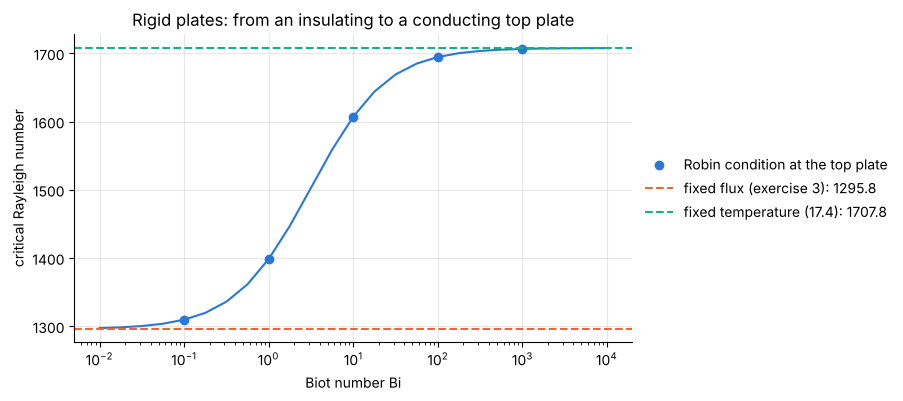

In [10]:
Bi_values = np.array([0.1, 1.0, 10.0, 100.0, 1000.0])
robin = np.array([critical_point(lambda k: ra_robin_top(k, Bi=Bi), (1.5, 4.0)) for Bi in Bi_values])
print("    Bi       Ra_c       k_c")
for Bi, (k_c, Ra_c) in zip(Bi_values, robin):
    print(f"{Bi:7.1f}  {Ra_c:9.3f}   {k_c:.4f}")
Bi_dense = np.geomspace(0.01, 1e4, 25)
Ra_dense = np.array([critical_point(lambda k: ra_robin_top(k, Bi=Bi), (1.5, 4.0))[1] for Bi in Bi_dense])

fig, ax = plt.subplots(figsize=(7.2, 4))
ax.semilogx(Bi_dense, Ra_dense, color="C0", lw=1.5)
ax.semilogx(Bi_values, robin[:, 1], "o", color="C0", label="Robin condition at the top plate")
ax.axhline(Ra_flux, color="C1", ls="--", lw=1.5, label=f"fixed flux (exercise 3): {Ra_flux:.1f}")
ax.axhline(Ra_rr, color="C2", ls="--", lw=1.5, label=f"fixed temperature (17.4): {Ra_rr:.1f}")
ax.set(xlabel="Biot number Bi", ylabel="critical Rayleigh number", title="Rigid plates: from an insulating to a conducting top plate")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [11]:
# verify: the curve is monotonic, lies between the two limits and reaches each of them
assert np.all(np.diff(Ra_dense) > 0) and Ra_flux < Ra_dense[0] and Ra_dense[-1] < Ra_rr
assert abs(Ra_dense[0] - Ra_flux) < 2.0 and abs(Ra_dense[-1] - Ra_rr) < 0.2         # Bi = 0.01 and Bi = 10 000
assert abs(critical_point(lambda k: ra_robin_top(k, Bi=1e8), (1.5, 4.0))[1] - Ra_rr) < 1e-3
assert np.all(np.diff(robin[:, 0]) > 0)                                             # the rolls narrow as the plate conducts better

**Answer.** $Ra_c = 1309.5,\ 1398.5,\ 1607.1,\ 1694.6,\ 1706.4$ for
$Bi = 0.1,\ 1,\ 10,\ 100,\ 1000$. The curve rises monotonically from the fixed-flux value
1295.8 to the fixed-temperature value 1707.8, and nearly all of the change takes place
between $Bi = 0.1$ and $Bi = 100$. Outside that range the plate may be treated as one of the
two ideal cases. At $Bi = 1$ the threshold is 1398.5, much closer to the insulating limit than
to the conducting one, so a plate has to conduct well before the classical number applies.

## Exercise 5

Air at 300 K ($\nu = 1.6\times10^{-5}$ m²/s, $\kappa = 2.2\times10^{-5}$ m²/s,
$\beta = 1/300$ 1/K, $g = 9.81$ m/s²) fills a horizontal gap between two rigid plates, the
lower one 10 K warmer. (a) What is the widest gap that stays free of convection? (b) For a
gap 1.5 times that width, compute the growth rate of the fastest-growing disturbance by
maximizing $\sigma$ over $k$ with `growth_rate`, and convert it to an e-folding time in
seconds.

(a) The gap is free of convection as long as $Ra < Ra_c = 1707.762$. Solve the definition of
$Ra$ for the depth: $d_c = \big(Ra_c\,\nu\kappa/(g\beta\,\Delta T)\big)^{1/3}$.

(b) $Ra$ grows as $d^3$, so a gap 1.5 times wider has $Ra = 1.5^3\,Ra_c = 3.375\,Ra_c$. The
Prandtl number is $\nu/\kappa$. Maximize the real part of $\sigma$ over $k$. The result is in
units of $\kappa/d^2$, with $d$ the actual gap, so the e-folding time is $d^2/(\kappa\,\sigma)$.

(a) widest gap without convection: d_c = 12.25 mm
(b) gap 18.38 mm: Ra = 5763.7 = 3.375 Ra_c, Pr = 0.727
    fastest growth at k = 3.913 (k_c = 3.116): σ = 21.003 κ/d²,  σ at k_c: 19.535
    d²/κ = 15.35 s, so the e-folding time is 0.73 s


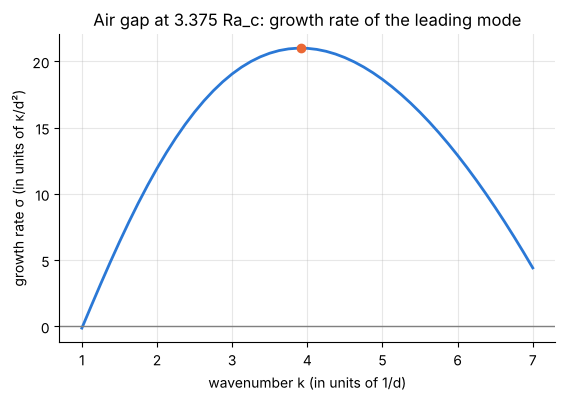

In [12]:
nu, kappa, beta, g, dT = 1.6e-5, 2.2e-5, 1 / 300, 9.81, 10.0
d_c = (Ra_rr * nu * kappa / (g * beta * dT)) ** (1 / 3)
d = 1.5 * d_c
Pr, Ra = nu / kappa, g * beta * dT * d**3 / (nu * kappa)

def sigma_of_k(k, N=20):
    return growth_rate(Ra, Pr, k, *rigid_blocks(k, N)).real

best = minimize_scalar(lambda k: -sigma_of_k(k), bounds=(1.0, 8.0), method="bounded", options={"xatol": 1e-7})
k_fast, sigma_fast = best.x, -best.fun
time_unit = d**2 / kappa
print(f"(a) widest gap without convection: d_c = {1e3 * d_c:.2f} mm")
print(f"(b) gap {1e3 * d:.2f} mm: Ra = {Ra:.1f} = {Ra / Ra_rr:.3f} Ra_c, Pr = {Pr:.3f}")
print(f"    fastest growth at k = {k_fast:.3f} (k_c = {k_rr:.3f}): σ = {sigma_fast:.3f} κ/d²,  σ at k_c: {sigma_of_k(k_rr):.3f}")
print(f"    d²/κ = {time_unit:.2f} s, so the e-folding time is {time_unit / sigma_fast:.2f} s")

k_plot = np.linspace(1.0, 7.0, 49)
fig, ax = plt.subplots()
ax.plot(k_plot, [sigma_of_k(k) for k in k_plot])
ax.plot(k_fast, sigma_fast, "o", color="C1")
ax.axhline(0, color="0.5", lw=1)
ax.set(xlabel="wavenumber k (in units of 1/d)", ylabel="growth rate σ (in units of κ/d²)", title="Air gap at 3.375 Ra_c: growth rate of the leading mode");

The check on the growth rate uses no eigenvalue solver. The linear equations are
$B\,\dot{\mathbf{x}} = A\,\mathbf{x}$, so $\mathbf{x}(t) = e^{tB^{-1}A}\,\mathbf{x}(0)$. Starting
from an arbitrary disturbance, the matrix exponential gives the solution at two times, and the
growth of its size between them must be $e^{\sigma\,\Delta t}$ once the decaying modes have
died out.

In [13]:
# verify: (a) the growth rate vanishes at the critical gap; (b) growth measured from the solution of the linear equations
L, L4 = rigid_blocks(k_rr, 20)
assert abs(growth_rate(g * beta * dT * d_c**3 / (nu * kappa), Pr, k_rr, L, L4).real) < 1e-6
assert abs(d_c - 12.25e-3) < 0.01e-3

L, L4 = rigid_blocks(k_fast, 20)
n = len(L)
A = np.block([[L4, -Ra * k_fast**2 * np.eye(n)], [np.eye(n), L]])
B = np.block([[L / Pr, np.zeros((n, n))], [np.zeros((n, n)), np.eye(n)]])
half_unit = expm(0.5 * solve(B, A))                                       # the solution operator over half a time unit
state_1 = half_unit @ np.ones(2 * n)
state_2 = half_unit @ state_1
sigma_measured = np.log(np.linalg.norm(state_2) / np.linalg.norm(state_1)) / 0.5
print(f"growth rate measured from the time evolution: {sigma_measured:.6f}   from the eigenvalue: {sigma_fast:.6f}")
assert abs(sigma_measured / sigma_fast - 1) < 1e-6
assert abs(sigma_of_k(k_fast, N=28) / sigma_fast - 1) < 1e-7              # unchanged at a higher resolution
assert abs(growth_rate(Ra, Pr, k_fast, L, L4).imag) < 1e-8                # a real eigenvalue: steady rolls
assert sigma_fast > sigma_of_k(k_rr) > 0 and k_fast > k_rr

growth rate measured from the time evolution: 21.003044   from the eigenvalue: 21.003044


**Answer.** (a) The gap stays free of convection up to $d_c = 12.25$ mm. (b) At 18.38 mm the
Rayleigh number is $3.375\,Ra_c = 5763.7$ and $Pr = 0.727$. The fastest disturbance has
$k = 3.913$, somewhat narrower rolls than at onset ($k_c = 3.116$), and grows at
$\sigma = 21.00\,\kappa/d^2$. With $d^2/\kappa = 15.35$ s the e-folding time is 0.73 s: a
disturbance grows a thousandfold in about five seconds. For the designer of double glazing or
of a solar collector cover this means that there is no intermediate regime to rely on. An air
gap that is 50 per cent too wide for a 10 K difference is convecting within seconds, and its
insulating value is then no longer that of still air.